# TP4 — Régularisation et augmentation

**Cours :** Réseaux de neurones convolutifs (CNN) — 30 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 2 h · **Barème :** 10 points

---

## Objectifs

- Mesurer le surapprentissage et l'effet de trois stratégies de régularisation.
- Comparer les courbes train / test entre configurations.
- Comprendre quand l'augmentation aide et quand elle ne suffit plus.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter les cellules **dans l'ordre**. L'entraînement tourne sur **CPU** : quelques minutes.
- Les cellules **« À vous »** sont évaluées.
- Toutes les graines sont fixées : deux exécutions donnent le même résultat.

In [1]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(4112); np.random.seed(4112)
torch.set_num_threads(2)
device = 'cpu'
print('torch', torch.__version__, '| appareil :', device)

torch 2.15.0+cpu | appareil : cpu


## 1. Surapprentissage, régularisation, augmentation

On entraîne **trois fois le même réseau** sur le même jeu de données, en changeant
un seul réglage à chaque fois.

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

tf = transforms.Compose([transforms.Pad(2),
                         transforms.ToTensor(),
                         transforms.Normalize((0.1307,), (0.3081,))])
train_full = datasets.MNIST("../data", train=True, download=True, transform=tf)
test_full = datasets.MNIST("../data", train=False, download=True, transform=tf)

N_TRAIN, N_TEST = 4000, 1000
# jeu volontairement plus petit que celui du TP3 : le surapprentissage apparait mieux
tr = Subset(train_full, range(N_TRAIN))
te = Subset(test_full, range(N_TEST))
train_loader = DataLoader(tr, batch_size=64, shuffle=True)
test_loader = DataLoader(te, batch_size=256)
print(len(tr), "images d'entrainement,", len(te), "de test")

4000 images d'entrainement, 1000 de test


In [3]:
class LeNet(nn.Module):
    def __init__(self, dropout=0.0, n_classes=10):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, 5); self.c3 = nn.Conv2d(6, 16, 5)
        self.c5 = nn.Conv2d(16, 120, 5); self.f6 = nn.Linear(120, 84)
        self.drop = nn.Dropout(dropout); self.out = nn.Linear(84, n_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        x = F.relu(self.c5(x))
        x = F.relu(self.f6(self.drop(torch.flatten(x, 1))))
        return self.out(x)


def entraine(dropout=0.0, augmenter=False, epoques=3, lr=1e-3):
    tf_ = transforms.Compose([
        transforms.Pad(2),
        transforms.RandomAffine(degrees=12, translate=(0.08, 0.08)),
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))] if augmenter else [
        transforms.Pad(2), transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))])
    ds = Subset(datasets.MNIST("../data", train=True, download=True, transform=tf_), range(N_TRAIN))
    dl = DataLoader(ds, batch_size=64, shuffle=True)
    m = LeNet(dropout=dropout).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr); pf = nn.CrossEntropyLoss()

    def acc(loader, m):
        m.eval(); b = t = 0
        with torch.no_grad():
            for x, y in loader:
                b += (m(x).argmax(1) == y).sum().item(); t += y.size(0)
        return b / t

    hist = {"train": [], "test": []}
    for ep in range(epoques):
        m.train()
        for x, y in dl:
            opt.zero_grad(); pf(m(x), y).backward(); opt.step()
        hist["train"].append(acc(train_loader, m)); hist["test"].append(acc(test_loader, m))
        print(f"  epoque {ep+1}: train={hist['train'][-1]:.1%}  test={hist['test'][-1]:.1%}")
    return hist

print("=== A. sans regularisation ===")
h_A = entraine(dropout=0.0, augmenter=False)
print("\n=== B. avec dropout (p = 0,5) ===")
h_B = entraine(dropout=0.5, augmenter=False)
print("\n=== C. avec dropout + augmentation ===")
h_C = entraine(dropout=0.5, augmenter=True)

=== A. sans regularisation ===


  epoque 1: train=83.6%  test=80.2%


  epoque 2: train=92.5%  test=89.5%


  epoque 3: train=94.7%  test=92.8%

=== B. avec dropout (p = 0,5) ===


  epoque 1: train=77.5%  test=74.9%


  epoque 2: train=92.7%  test=89.9%


  epoque 3: train=95.3%  test=93.3%

=== C. avec dropout + augmentation ===


  epoque 1: train=75.8%  test=71.7%


  epoque 2: train=87.6%  test=85.8%


  epoque 3: train=93.0%  test=92.0%


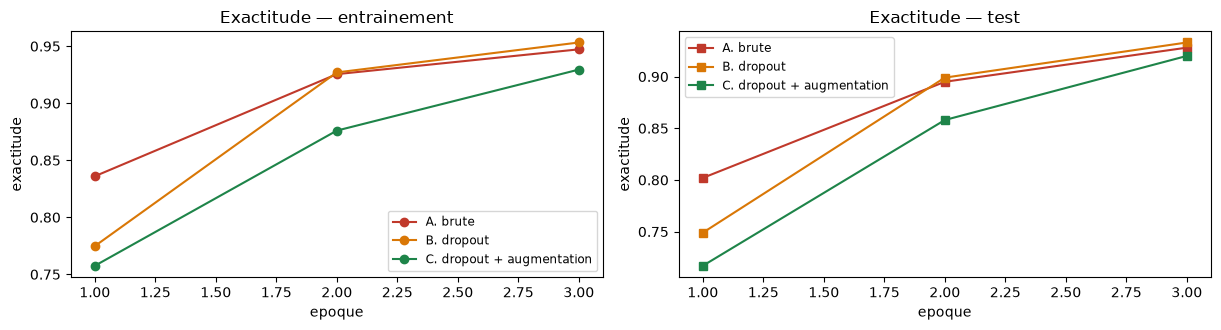

ecart train - test en fin d'entrainement :
   A : +1.9%
   B : +2.0%
   C : +0.9%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.4))
for h, nom, coul in [(h_A, "A. brute", "#C0392B"), (h_B, "B. dropout", "#D97706"),
                     (h_C, "C. dropout + augmentation", "#1E8449")]:
    axes[0].plot(range(1, len(h["train"])+1), h["train"], "o-", color=coul, label=nom)
    axes[1].plot(range(1, len(h["test"])+1), h["test"], "s-", color=coul, label=nom)
axes[0].set_title("Exactitude — entrainement"); axes[1].set_title("Exactitude — test")
for a in axes:
    a.set_xlabel("epoque"); a.set_ylabel("exactitude"); a.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

ecarts = {n: h["train"][-1] - h["test"][-1] for n, h in [("A", h_A), ("B", h_B), ("C", h_C)]}
print("ecart train - test en fin d'entrainement :")
for n, e in ecarts.items():
    print(f"   {n} : {e:+.1%}")

## 2. Voir l'augmentation

L'augmentation fabrique des variantes plausibles de chaque image. Le réseau voit ainsi
davantage de situations sans qu'on collecte de nouvelles données.

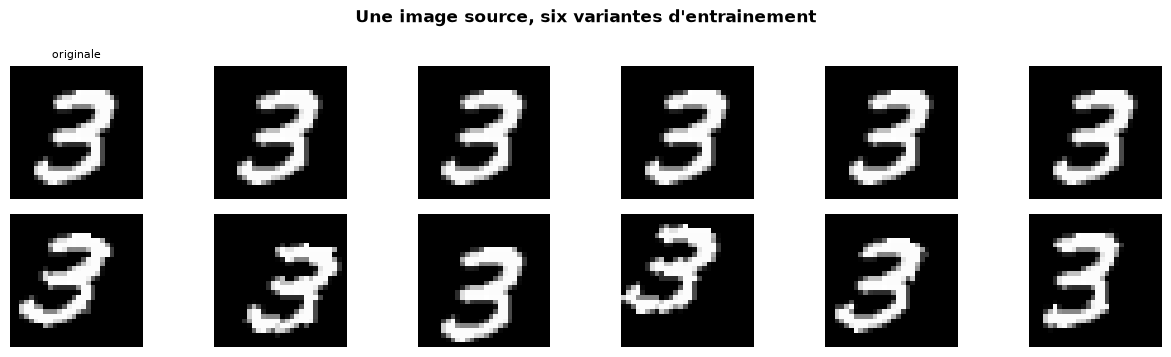

In [5]:
base = datasets.MNIST("../data", train=True, download=True,
                        transform=transforms.ToTensor())
img = base[7][0]
aug = transforms.Compose([transforms.RandomAffine(degrees=15, translate=(0.12, 0.12))])

fig, axes = plt.subplots(2, 6, figsize=(12.5, 3.6))
for j in range(6):
    axes[0, j].imshow(img[0], cmap="gray"); axes[0, j].set_title("originale" if j == 0 else "", fontsize=8)
    axes[1, j].imshow(aug(img)[0], cmap="gray")
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[1, 0].set_ylabel("augmentee")
plt.suptitle("Une image source, six variantes d'entrainement", fontweight="bold")
plt.tight_layout(); plt.show()

## 3. À vous

**Question 1.** Pourquoi l'augmentation est-elle appliquée **uniquement** au jeu
d'entraînement et jamais à celui de test ?

**Question 2.** Le dropout ralentit l'apprentissage par époque mais améliore le test :
expliquez ce compromis.

**Question 3.** Avec un jeu d'entraînement beaucoup plus grand, le bénéfice du dropout
diminuerait-il ou augmenterait-il ? Justifiez.

In [6]:
# ---- À VOUS ----
# 1)
# 2)
# 3)

## 4. Synthèse

| Régularisation | Principe | Coût |
|---|---|---|
| **Dropout** | éteindre aléatoirement des neurones | apprentissage plus lent |
| **Augmentation** | multiplier les variantes des données | calcul par époque |
| **Weight decay** | pénaliser les grands poids | 1 hyperparamètre de plus |
| **Early stopping** | arrêter au minimum de validation | nécessite un jeu de validation |
| **Batch norm** | recaler les activations | quasi gratuit |

**Le meilleur levier reste… davantage de données.**